# Chapter 2 · Random variables

*Book 3 · Probability · Shelf I*

**Builds on:** [Chapter 1](01-counting-and-axioms.ipynb) -- events and their probabilities.
**You will:** describe a random quantity by its distribution (pmf, pdf, cdf), compute its expected
value and variance, use linearity of expectation, and see why the expectation of a function is not
the function of the expectation -- the trap in every risk calculation.

A **random variable** turns an outcome into a number: the sum of two dice, the mass of a falling
rock. Its **distribution** says how likely each value is -- a probability mass function for
discrete values, a density for continuous ones, and for both the cumulative distribution function
$F(x) = P(X \le x)$.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

from ds_toolbox import io, viz

viz.use_style()
rng = np.random.default_rng(2)

## A discrete variable: the sum of two dice

E[sum] = 7.000, Var[sum] = 5.833


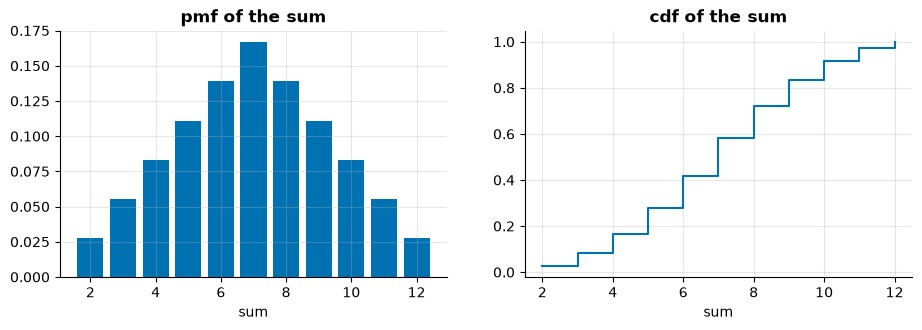

In [2]:
faces = np.arange(1, 7)
sums = (faces[:, None] + faces[None, :]).ravel()
values, counts = np.unique(sums, return_counts=True)
pmf = counts / counts.sum()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].bar(values, pmf, color=viz.PALETTE[0])
axes[0].set(title="pmf of the sum", xlabel="sum")
axes[1].step(values, np.cumsum(pmf), where="post")
axes[1].set(title="cdf of the sum", xlabel="sum")
mean = (values * pmf).sum()
var = ((values - mean) ** 2 * pmf).sum()
print(f"E[sum] = {mean:.3f}, Var[sum] = {var:.3f}")

## Linearity of expectation

$E[X + Y] = E[X] + E[Y]$ -- always, even when $X$ and $Y$ depend on each other. One die has
$E = 3.5$, so two have 7, with no table needed. Variances add only for independent variables:
$\mathrm{Var}(X + Y) = 35/12 + 35/12 = 5.83$.

## A continuous variable: the mass of a rock

The probability book's running example is a slope above a road (the challenge). One season of
rockfalls, seeded by the toolbox -- invented, but shaped like a real record. A density's area, not
its height, is a probability.

P(mass > 1000 kg) = area right of 1000 = 0.201; observed share 0.197


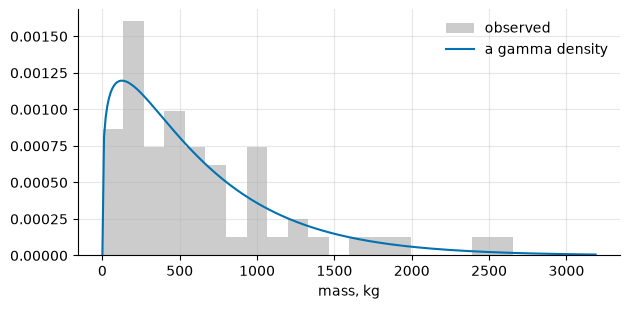

In [3]:
season = io.load_sample("rockfall_season.csv", parse_dates=["time"])
mass = season.loc[season.zone == "zone 1", "mass"]
fit = stats.gamma(*stats.gamma.fit(mass, floc=0))
x = np.linspace(0, mass.max() * 1.2, 300)
plt.figure(figsize=(7, 3.2))
plt.hist(mass, bins=20, density=True, color="0.8", label="observed")
plt.plot(x, fit.pdf(x), label="a gamma density")
plt.xlabel("mass, kg")
plt.legend()
print(f"P(mass > 1000 kg) = area right of 1000 = {fit.sf(1000):.3f}; observed share {(mass > 1000).mean():.3f}")

## The expectation of a function is not the function of the expectation

A rock's energy is $E = \tfrac12 m v^2$. Plug in the average mass and the average speed and you get
one number; average the energies of the rocks themselves and you get another. Because $v^2$ is
convex, the second is larger (Jensen's inequality) -- and it is the right one.

In [4]:
z1 = season[season.zone == "zone 1"]
plug_in = 0.5 * z1.mass.mean() * z1.speed.mean() ** 2 / 1000
average = (0.5 * z1.mass * z1.speed ** 2 / 1000).mean()
print(f"energy of the average rock: {plug_in:.1f} kJ | average energy of the rocks: {average:.1f} kJ")

energy of the average rock: 25.3 kJ | average energy of the rocks: 26.5 kJ


The gap grows with the spread. For risk it is worse than the averages suggest: what breaks a net is
not the average rock but the rare large one -- a question about the *tail* of the distribution,
which chapter 3 and the challenge are about.

## What to remember

- A random variable has a distribution: pmf or pdf, and always a cdf.
- Expectation is linear; variance adds only under independence.
- $E[g(X)] \ne g(E[X])$ for a nonlinear $g$ -- compute the expectation of the quantity you care about.

## Exercises

1. Compute $E[\max(D_1, D_2)]$ for two dice by enumeration and by simulation.
2. Show by simulation that $E[XY] \ne E[X]E[Y]$ when $Y = X + $ noise.
3. How large is the Jensen gap for zone 2's rocks, which are faster?

**Next:** [Chapter 3 · The common distributions](03-the-common-distributions.ipynb)